# 04 - Sensibilità all'orario del pasto e alla velocità di assorbimento (adult#001, 60 g)

**Obiettivo.** Come suggerito dalla co-relatrice, osservare come cambia la risposta dell'anello chiuso al variare
(a) dell'istante di assunzione del pasto e (b) della velocità di assorbimento dei carboidrati, a parità di quantità (60 g).

La velocità di assorbimento si modifica con `assorb_scale`, che scala insieme le costanti dello svuotamento gastrico
(`kmax`, `kmin`) e dell'assorbimento intestinale (`kabs`) del modello UVa/Padova: 0.5 è un pasto lento, 2 un pasto rapido.
Scalare solo `kabs` non basta: nel modello la dinamica del pasto è dominata dallo svuotamento gastrico.
La velocità di ingestione resta quella di simglucose (5 g/min).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
SEED = 1                                  # seme del rumore del sensore (uguale per tutti i controllori)
COL = {"PID senza AW": "tab:gray", "PID": "tab:red", "PID cons.": "tab:orange",
       "PID+PLGS": "tab:green", "PID+IOB": "tab:purple", "PID+IOB+PLGS": "tab:blue"}
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.13.16
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


In [2]:
def finestra(df):
    """Solo la finestra di analisi (08:00-24:00): l'assestamento 00:00-08:00 non entra né nei grafici né nelle metriche."""
    return df[df.t_h >= A.WARMUP_H]

def decora(ax, meal_h=A.MEAL_CLOCK_H, banda=True):
    """Linea del pasto e griglia; banda 70-180 mg/dL solo sui pannelli di glicemia."""
    if banda:
        ax.axhspan(70, 180, color="green", alpha=0.12)
    ax.axvline(meal_h, color="k", ls=":", lw=1.2); ax.grid(ls=":", alpha=0.5)

def tabella(risultati, chiavi):
    """risultati: dict {chiave: DataFrame}; chiavi: nomi delle colonne-indice per la tabella."""
    rows = []
    for k, df in risultati.items():
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(chiavi, k)), **{m: round(float(v), 1) for m, v in A.metrics(df).items()}})
    return pd.DataFrame(rows)

In [3]:
PAZIENTE = "adult#001"; CHO = 60.0
NOMI = ["PID", "PID+IOB+PLGS"]
display(U.scenario_table(PAZIENTE, CHO, SEED))

,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore di simglucose),-
5,Pompa di infusione,Insulet,-
6,Seme casuale del sensore,1,-
7,Inizio simulazione,00:00,ora del giorno
8,Assestamento escluso dalle metriche,00:00-08:00,ora del giorno
9,Finestra di analisi,08:00-24:00,ora del giorno


### Unità di misura delle variabili salvate
| Variabile | Unità | Significato |
|---|---|---|
| `t_h` | h | ora del giorno (la simulazione parte alle 00:00) |
| `CGM` | mg/dL | misura del sensore, con rumore: è l'unica grandezza vista dal controllore |
| `BG` | mg/dL | glicemia plasmatica del modello UVa/Padova (Gp/Vg), usata per le metriche |
| `Gsub` | mg/dL | glicemia sottocutanea senza rumore (`info['bg']` di simglucose) |
| `Insulin_Uh` | U/h | velocità di infusione comandata |
| `IOB` | U | insulina attiva netta stimata dal controllore (eccesso rispetto al basale) |
| `IOB_vero` | U | insulina sottocutanea netta del modello (Isc1 + Isc2 meno l'equilibrio basale) |
| `Vincolo` | - | vincolo attivo nel passo: `iob`, `plgs`, `sat_alta`, `sat_bassa` o vuoto |

Metriche: TIR, TAR, TBR in % del tempo nella finestra 08:00-24:00; `TIR_post6h` nelle 6 h dopo il pasto;
`TBR_tardivo` dalle 3 h dopo il pasto alle 24:00; picco e nadir in mg/dL; `insulina_tot` in U nella finestra.

## 1. Orario del pasto

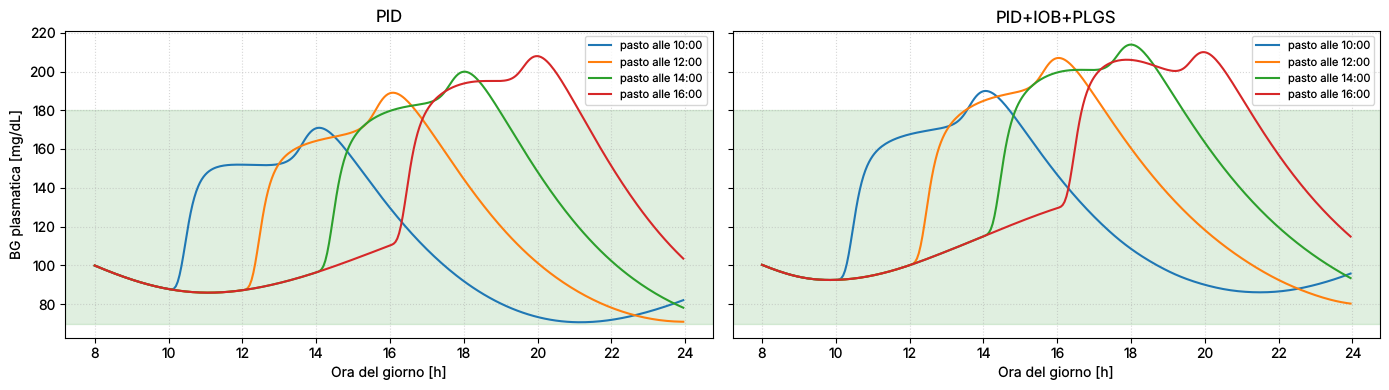

,Orario,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,10:00,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,171.0,70.7,26.2,531.8,191.3,0.0,0.0,0.0,0.0,9.3,0.8
1,10:00,PID+IOB+PLGS,92.8,7.2,0.0,0.0,0.0,0.0,80.8,190.0,86.1,23.0,517.1,277.4,7.4,4.8,63.0,8.0,103.8,1.1
2,12:00,PID,93.4,6.6,0.0,0.0,0.0,0.0,82.5,189.1,70.9,28.4,566.0,267.7,6.4,4.7,0.0,0.0,9.8,0.8
3,12:00,PID+IOB+PLGS,76.6,23.4,0.0,0.0,0.0,0.0,37.5,207.0,80.3,25.7,598.2,361.8,47.4,5.3,68.0,5.0,118.0,1.1
4,14:00,PID,81.6,18.4,0.0,0.0,0.0,0.0,50.8,199.9,78.2,29.8,590.0,325.9,24.9,5.0,0.0,0.0,9.6,0.9
5,14:00,PID+IOB+PLGS,71.6,28.4,0.0,0.0,0.0,0.0,24.2,213.9,92.5,26.8,608.4,413.5,89.8,5.4,78.0,5.0,131.1,1.0
6,16:00,PID,74.4,25.6,0.0,0.0,0.0,0.0,31.7,208.0,85.9,28.5,615.0,377.4,63.2,5.1,0.0,0.0,8.9,0.9
7,16:00,PID+IOB+PLGS,71.6,28.4,0.0,0.0,0.0,0.0,24.2,210.1,92.5,25.6,588.5,424.8,96.2,5.2,81.0,4.0,136.4,1.0


In [4]:
ORARI = [10.0, 12.0, 14.0, 16.0]
Ro = {(f"{int(h):02d}:00", n): A.simulate(PAZIENTE, CHO, A.CFG[n], seed=SEED, meal_clock_h=h)[0] for h in ORARI for n in NOMI}
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for j, n in enumerate(NOMI):
    for h in ORARI:
        d = finestra(Ro[(f"{int(h):02d}:00", n)]); ax[j].plot(d.t_h, d.BG, label=f"pasto alle {int(h)}:00")
    ax[j].axhspan(70, 180, color="green", alpha=0.12); ax[j].grid(ls=":", alpha=0.5); ax[j].set_title(n); ax[j].legend(fontsize=8)
    ax[j].set_xlabel("Ora del giorno [h]")
ax[0].set_ylabel("BG plasmatica [mg/dL]"); plt.tight_layout(); plt.show()
rows = []
for (o, n), df in Ro.items():
    m = A.metrics(df, meal_h=float(o[:2]))
    rows.append({"Orario": o, "Controllore": n, **{k: round(float(v), 1) for k, v in m.items()}})
display(pd.DataFrame(rows))

**Attenzione.** Con un pasto più tardo resta meno tempo prima delle 24:00: il `TBR_tardivo` di un pasto alle 16:00 copre
solo 5 ore. Per confrontare gli orari conviene guardare soprattutto `TIR_post6h`, picco e nadir.

## 2. Velocità di assorbimento

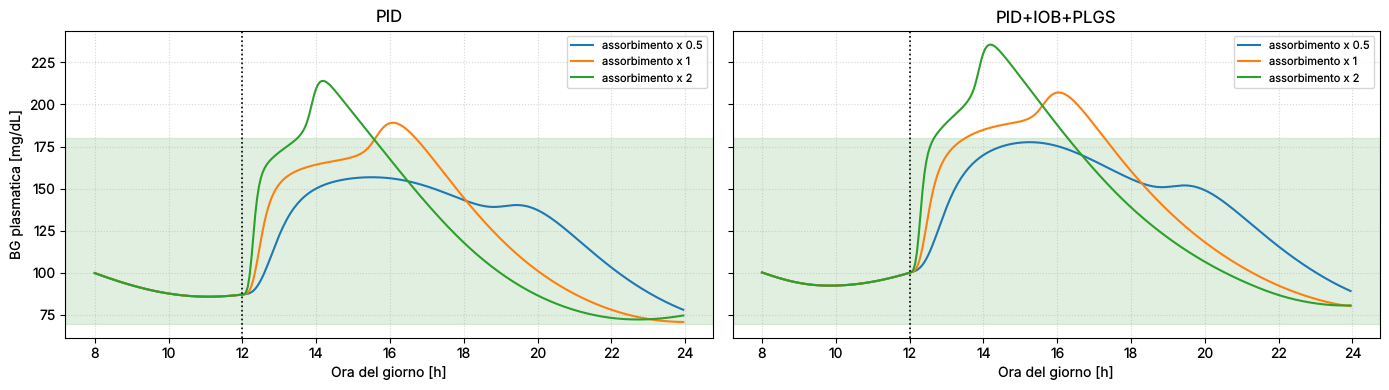

,Assorbimento x,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,0.5,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,156.8,78.2,30.7,412.5,172.8,0.0,0.0,0.0,0.0,9.2,0.8
1,0.5,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,177.6,89.3,27.5,482.4,253.5,0.0,0.0,74.0,5.0,118.6,1.0
2,1.0,PID,93.4,6.6,0.0,0.0,0.0,0.0,82.5,189.1,70.9,28.4,566.0,267.7,6.4,4.7,0.0,0.0,9.8,0.8
3,1.0,PID+IOB+PLGS,76.6,23.4,0.0,0.0,0.0,0.0,37.5,207.0,80.3,25.7,598.2,361.8,47.4,5.3,68.0,5.0,118.0,1.1
4,2.0,PID,87.2,12.8,0.0,0.0,0.0,0.0,65.8,213.9,72.4,27.0,624.9,290.5,36.7,3.6,0.0,0.0,10.7,0.9
5,2.0,PID+IOB+PLGS,77.5,22.5,0.0,0.0,0.0,0.0,40.0,235.4,80.7,24.9,638.5,400.4,96.5,4.3,66.0,7.0,117.5,1.1


In [5]:
SCALE = [0.5, 1.0, 2.0]
Ra = {(s, n): A.simulate(PAZIENTE, CHO, A.CFG[n], seed=SEED, assorb_scale=s)[0] for s in SCALE for n in NOMI}
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for j, n in enumerate(NOMI):
    for s in SCALE:
        d = finestra(Ra[(s, n)]); ax[j].plot(d.t_h, d.BG, label=f"assorbimento x {s:g}")
    decora(ax[j]); ax[j].set_title(n); ax[j].legend(fontsize=8); ax[j].set_xlabel("Ora del giorno [h]")
ax[0].set_ylabel("BG plasmatica [mg/dL]"); plt.tight_layout(); plt.show()
display(tabella(Ra, ["Assorbimento x", "Controllore"]))